In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, Matern

In [ ]:
# Original dataset has 30 rows

In [2]:
X = np.load(r"initial_data\function_4\initial_inputs.npy")
Y = np.load(r"initial_data\function_4\initial_outputs.npy")
df = pd.DataFrame({
    'x1': X[:,0],
    'x2': X[:,1],
    'x3': X[:,2],
    'x4': X[:,3],
    'y': Y
})
df.index = df.index+1
df

,x1,x2,x3,x4,y
1,0.896981,0.725628,0.175404,0.701694,-22.108288
2,0.889356,0.499588,0.539269,0.508783,-14.601397
3,0.250946,0.033693,0.145380,0.494932,-11.699932
4,0.346962,0.006250,0.760564,0.613024,-16.053765
5,0.124871,0.129770,0.384400,0.287076,-10.069633
6,0.801303,0.500231,0.706645,0.195103,-15.487083
7,0.247708,0.060445,0.042186,0.441324,-12.681685
8,0.746702,0.757092,0.369353,0.206566,-16.026400
9,0.400665,0.072574,0.886768,0.243842,-17.049235
10,0.626071,0.586751,0.438806,0.778858,-12.741766


In [6]:
print(f'Best output value so far:\n {max(Y)}')
print(f'Corresponding x values:\n {X[np.argmax(Y)]}')
print(f'Best query output: \n Query {np.argmax(Y[30:])+1}: {max(Y[30:])}')
print(f'Improvement over last:\n {max(Y)} - {max(Y[:(len(Y)-1)])} = {max(Y)-max(Y[:(len(Y)-1)])}')

Best output value so far:
 0.5696609000016051
Corresponding x values:
 [0.389907 0.406702 0.418185 0.413754]
Best query output: 
 Query 12: 0.5696609000016051
Improvement over last:
 0.5696609000016051 - 0.45669524819956253 = 0.11296565180204254


In [4]:
# Define the GP kernel: a constant (signal variance) scaling a Matern kernel.
# Matern with nu=2.5 gives smooth-but-not-infinitely-smooth functions (less rigid than RBF).
# Passing an array for length_scale makes it ARD (one length scale per input dimension),
# so the GP can learn which inputs matter more. Bounds stop the length scales going to extremes.
kernel = ConstantKernel(1.0) * Matern(
    length_scale=np.ones(X.shape[1]),     # Starting guess of 1.0 for each input dimension
    length_scale_bounds=(1e-3, 10),       # Allowed range for each length scale during tuning
    nu=2.5                                # Smoothness parameter (twice differentiable)
)
gp = GaussianProcessRegressor(
    kernel=kernel,
    alpha=1e-10,                          # Tiny noise term added to the diagonal for numerical stability
    normalize_y=True,                     # Standardise Y (zero mean, unit variance) before fitting
    n_restarts_optimizer=20,              # Re-run hyperparameter optimisation from 20 random starts to avoid poor local optima
    random_state = 42                     # Fixes the random restarts so results are reproducible
)

# Fit the GP to the observed inputs (X) and outputs (Y)
gp.fit(X, Y)

# Randomly sample 10,000 candidate points in the 4-dimensional input space
candidate_points = np.random.rand(10000,4)

# Get the GP's predicted mean and standard deviation (uncertainty) at each candidate
mu, sigma = gp.predict(candidate_points, return_std=True)

# Best observed value so far (we are maximising)
best_y = np.max(Y)
xi = 0   # Exploration parameter: larger values push the search towards more uncertain regions

# Expected gain of each candidate over the current best
improvement = mu - best_y - xi

# Standardised improvement (Z-score), computed only where sigma > 0 to avoid division by zero
Z = np.zeros_like(mu)
mask = sigma > 0
Z[mask] = improvement[mask] / sigma[mask]

# Expected Improvement (EI) formula:
#   improvement * CDF(Z)  -> exploitation (high predicted mean)
#   sigma * PDF(Z)        -> exploration (high uncertainty)
# Points with zero uncertainty keep EI = 0
EI = np.zeros_like(mu)
EI[mask] = (
    improvement[mask] * norm.cdf(Z[mask])
    + sigma[mask] * norm.pdf(Z[mask])
)

# Pick the candidate with the highest EI as the next point to query
next_point = candidate_points[np.argmax(EI)]

print("Next point:", np.round(next_point, 6))

# Sanity check: the GP's prediction at the chosen point
mean, std = gp.predict(next_point.reshape(-1,4), return_std=True)
print(f'Predicted mean: {mean}')
print(f'Predicted std: {std}')

Next point: [0.357167 0.383558 0.216754 0.353909]
Predicted mean: [0.05150574]
Predicted std: [1.38994897]


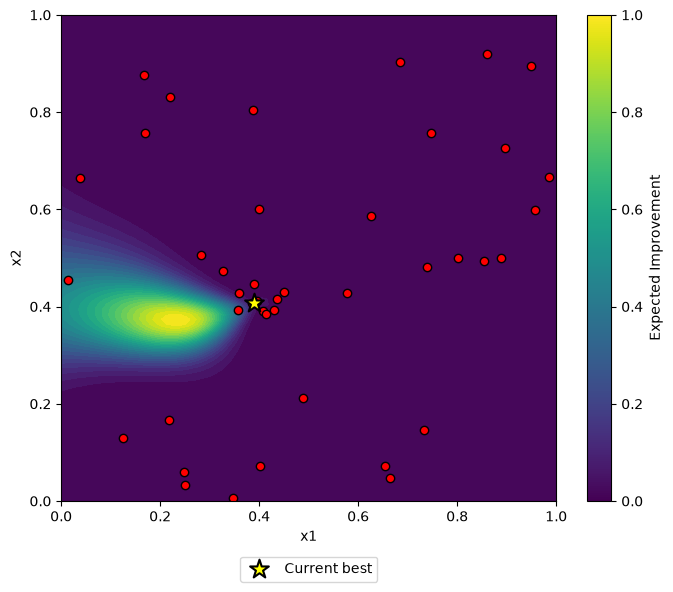

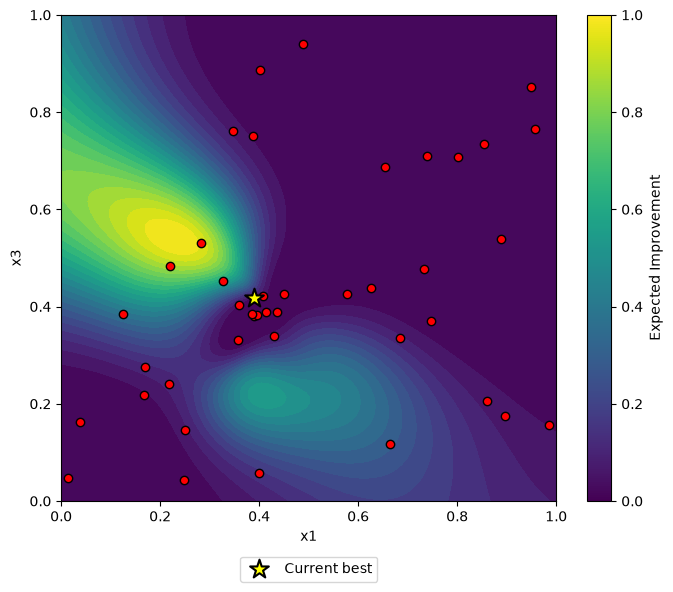

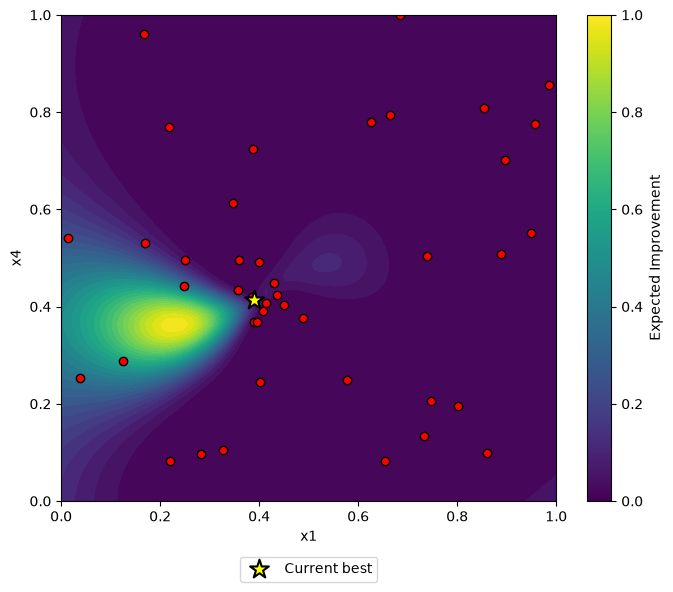

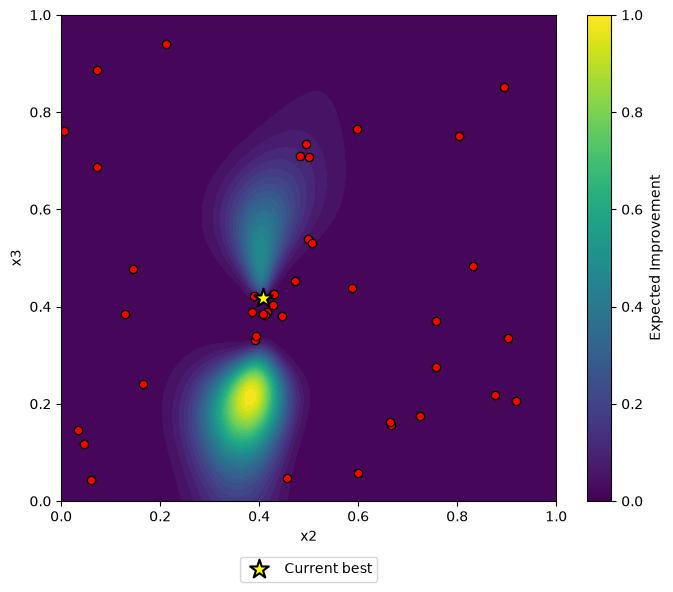

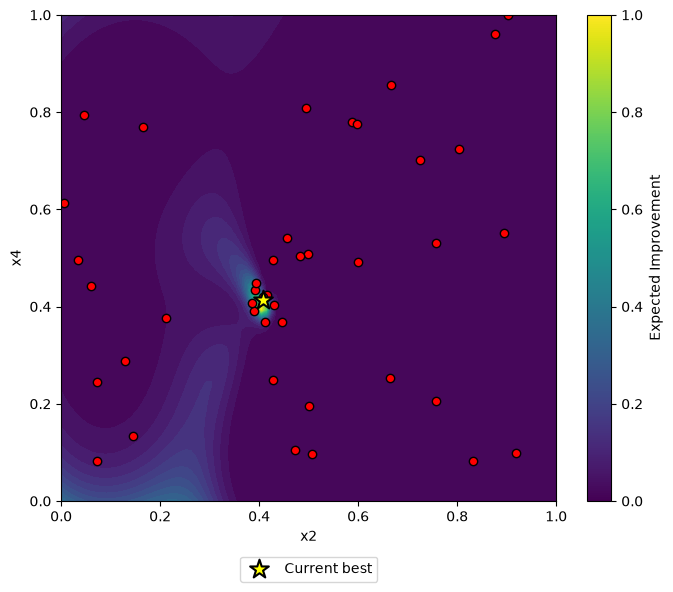

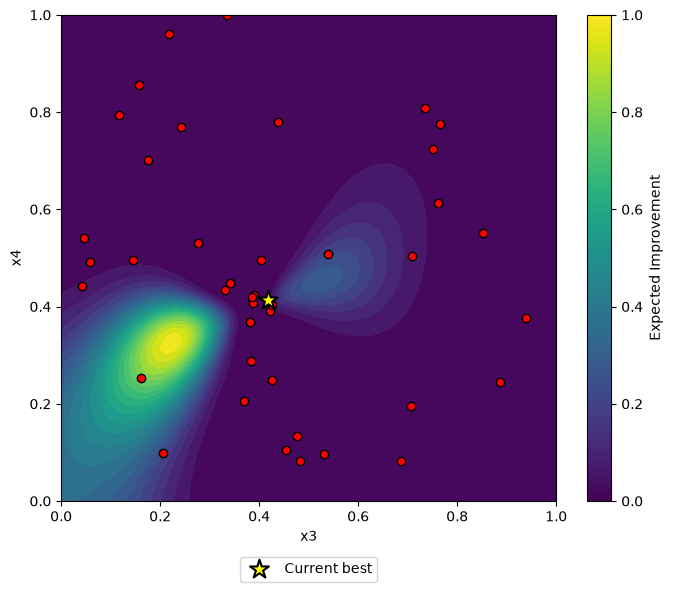

In [ ]:
def plot_EI_slice(gp, X, Y, dim1=0, dim2=1, resolution=100, xi=0):
    """
    Plot a 2D slice of the Expected Improvement acquisition function.

    Parameters
    ----------
    gp : fitted GaussianProcessRegressor
    X : observed inputs (n_samples, n_features)
    Y : observed outputs
    dim1 : first variable to plot
    dim2 : second variable to plot
    """

    # Use the best observed point as the "background": all dimensions not being
    # plotted are held fixed at this point's values
    best_point = X[np.argmax(Y)].copy()

    # Build a regular grid over the unit square for the two chosen dimensions
    x = np.linspace(0, 1, resolution)
    y = np.linspace(0, 1, resolution)

    xx, yy = np.meshgrid(x, y)

    # Create one full-dimensional row per grid cell, each starting as a copy of best_point
    grid = np.tile(best_point, (xx.size, 1))

    # Overwrite just the two plotted dimensions with the grid coordinates
    grid[:, dim1] = xx.ravel()
    grid[:, dim2] = yy.ravel()

    # GP predicted mean and uncertainty at every grid point
    mu, sigma = gp.predict(grid, return_std=True)

    # Best observed value so far (we are maximising)
    best_y = np.max(Y)

    # Expected gain of each grid point over the current best
    improvement = mu - best_y - xi

    EI = np.zeros_like(mu)

    mask = sigma > 0

    # Standardised improvement (Z-score)
    Z = np.zeros_like(mu)
    Z[mask] = improvement[mask] / sigma[mask]

    # Expected Improvement: exploitation term (CDF) + exploration term (PDF)
    EI[mask] = (
        improvement[mask] * norm.cdf(Z[mask])
        + sigma[mask] * norm.pdf(Z[mask])
    )

    plt.figure(figsize=(7,6))

    # Filled contour map of EI across the slice (brighter = higher EI)
    plt.contourf(xx, yy, EI.reshape(xx.shape), levels=30, cmap="viridis")

    # Overlay all observed points, projected onto the two plotted dimensions
    plt.scatter(
        X[:, dim1],
        X[:, dim2],
        c="red",
        edgecolor="black"
    )

    # Highlight the best observed point with a large yellow star
    plt.scatter(
    best_point[dim1],
    best_point[dim2],
    c="yellow",
    edgecolor="black",
    s=200,
    marker="*",
    linewidth=1.5,
    label="Current best"
    )

    plt.xlabel(f"x{dim1+1}")
    plt.ylabel(f"x{dim2+1}")

    plt.colorbar(label="Expected Improvement")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1))
    plt.tight_layout()
    plt.show()

plot_EI_slice(gp, X, Y, dim1=0, dim2=1)
plot_EI_slice(gp, X, Y, dim1=0, dim2=2)
plot_EI_slice(gp, X, Y, dim1=0, dim2=3)
plot_EI_slice(gp, X, Y, dim1=1, dim2=2)
plot_EI_slice(gp, X, Y, dim1=1, dim2=3)
plot_EI_slice(gp, X, Y, dim1=2, dim2=3)

In [ ]:
'''
1st point selected: [0.435953-0.415935-0.389022-0.424633]
Output: 0.45669524819956253

2nd point selected: [0.357247-0.392382-0.330472-0.434439]
Output: 0.12041647183222937

3rd point selected: [0.430629-0.393816-0.340355-0.447594]
Output: 0.018789953171645113

4th point selected: [0.359695-0.428531-0.403644-0.495657]
Output: -0.9846278343394768

5th point selected: [0.388631-0.446929-0.381322-0.368353]
Output: -0.14124155335023714

6th point selected: [0.408452-0.390142-0.422102-0.391689]
Output: 0.39052118258750257

7th point selected: [0.013055-0.455258-0.046932-0.541158]
Output: -14.488033871694494

8th point selected: [0.414000-0.385000-0.388000-0.408000] ---MANUALLY SELECTED---
Output: 0.349063287607589

9th point selected: [0.400548-0.600506-0.057359-0.490863]
Output: -9.712508948496076 

10th point selected: [0.449466-0.429658-0.425692-0.403375] ---SWITCHED TO MATERN KERNEL---
Output: 0.13103903782040094 

11th point selected: [0.395375-0.412043-0.381877-0.367472]
Output: 0.3964427202726566 

12th point selected: [0.389907-0.406702-0.418185-0.413754] --- xi reduced from 0.01 to 0.005 ---
Output: 0.5696609000016051   ---NEW BEST---

Final point selected: [0.385998-0.406731-0.384832-0.419533] --- xi reduced to 0 , SEVERAL RESTARTS REQUIRED for this point to be suggested ---
Output: 0.37077390040599

In [ ]:
# Updating data with new input-output pairs

# X_query1 = np.array([0.435953,0.415935,0.389022,0.424633], dtype=np.float64)
# Y_query1_output = np.array([0.45669524819956253], dtype=np.float64)
# X_updated = np.vstack((X, X_query1))
# Y_updated = np.append(Y, Y_query1_output)

# X_query2 = np.array([0.357247,0.392382,0.330472,0.434439], dtype=np.float64)
# Y_query2_output = np.array([0.12041647183222937], dtype=np.float64)
# X_updated = np.vstack((X, X_query2))
# Y_updated = np.append(Y, Y_query2_output)

# X_query3 = np.array([0.430629,0.393816,0.340355,0.447594], dtype=np.float64)
# Y_query3_output = np.array([0.018789953171645113], dtype=np.float64)
# X_updated = np.vstack((X, X_query3))
# Y_updated = np.append(Y, Y_query3_output)

# X_query4 = np.array([0.359695,0.428531,0.403644,0.495657], dtype=np.float64)
# Y_query4_output = np.array([-0.9846278343394768], dtype=np.float64)
# X_updated = np.vstack((X, X_query4))
# Y_updated = np.append(Y, Y_query4_output)

# X_query5 = np.array([0.388631,0.446929,0.381322,0.368353], dtype=np.float64)
# Y_query5_output = np.array([-0.14124155335023714], dtype=np.float64)
# X_updated = np.vstack((X, X_query5))
# Y_updated = np.append(Y, Y_query5_output)

# X_query6 = np.array([0.408452,0.390142,0.422102,0.391689], dtype=np.float64)
# Y_query6_output = np.array([0.39052118258750257], dtype=np.float64)
# X_updated = np.vstack((X, X_query6))
# Y_updated = np.append(Y, Y_query6_output)

# X_query7 = np.array([0.013055,0.455258,0.046932,0.541158], dtype=np.float64)
# Y_query7_output = np.array([-14.488033871694494], dtype=np.float64)
# X_updated = np.vstack((X, X_query7))
# Y_updated = np.append(Y, Y_query7_output)

# X_query8 = np.array([0.414000,0.385000,0.388000,0.408000], dtype=np.float64)
# Y_query8_output = np.array([0.349063287607589], dtype=np.float64)
# X_updated = np.vstack((X, X_query8))
# Y_updated = np.append(Y, Y_query8_output)

# X_query9 = np.array([0.400548,0.600506,0.057359,0.490863], dtype=np.float64)
# Y_query9_output = np.array([-9.712508948496076], dtype=np.float64)
# X_updated = np.vstack((X, X_query9))
# Y_updated = np.append(Y, Y_query9_output)

# X_query10 = np.array([0.449466,0.429658,0.425692,0.403375], dtype=np.float64)
# Y_query10_output = np.array([0.13103903782040094], dtype=np.float64)
# X_updated = np.vstack((X, X_query10))
# Y_updated = np.append(Y, Y_query10_output)

# X_query11 = np.array([0.395375,0.412043,0.381877,0.367472], dtype=np.float64)
# Y_query11_output = np.array([0.3964427202726566], dtype=np.float64)
# X_updated = np.vstack((X, X_query11))
# Y_updated = np.append(Y, Y_query11_output)

# X_query12 = np.array([0.389907,0.406702,0.418185,0.413754], dtype=np.float64)
# Y_query12_output = np.array([0.5696609000016051], dtype=np.float64)
# X_updated = np.vstack((X, X_query12))
# Y_updated = np.append(Y, Y_query12_output)

# X_query13 = np.array([0.385998,0.406731,0.384832,0.419533], dtype=np.float64)
# Y_query13_output = np.array([0.37077390040599], dtype=np.float64)
# X_updated = np.vstack((X, X_query13))
# Y_updated = np.append(Y, Y_query13_output)

In [ ]:
# Save new data to original files (initial_inputs.npy & initial_outputs.npy)

# np.save(r"initial_data\function_4\initial_inputs.npy", X_updated)
# np.save(r"initial_data\function_4\initial_outputs.npy", Y_updated)